<a href="https://colab.research.google.com/github/gerardagustina/breast-cancer-detection/blob/main/notebooks/01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   # Breast Cancer Detection — 01. Exploratory Data Analysis
   **Dataset:** BreastMNIST (breast ultrasound images, MedMNIST v2)  
   **Goal:** Understand the data before modelling: classes, balance, image properties.

In [2]:
   !pip install -q medmnist monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 63.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 9.9 MB/s eta 0:00:00


In [3]:
import medmnist
from medmnist import BreastMNIST

splits = {s: BreastMNIST(split=s, download=True, size=224) for s in ["train", "val", "test"]}

info = medmnist.INFO["breastmnist"]["label"]
print("Clases:", info)
print("Tamaños:", {s: len(d) for s, d in splits.items()})

100%|██████████| 30.9M/30.9M [01:28<00:00, 350kB/s]


Clases: {'0': 'malignant', '1': 'normal, benign'}
Tamaños: {'train': 546, 'val': 78, 'test': 156}


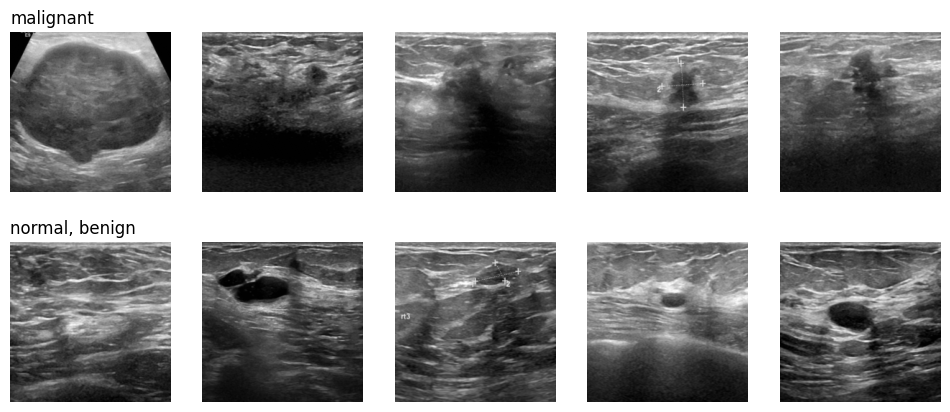

In [4]:
import numpy as np
import matplotlib.pyplot as plt

tr = splits["train"]
labels = tr.labels.ravel()

fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for c in [0, 1]:
    idx = np.where(labels == c)[0][:5]
    for j, i in enumerate(idx):
        ax[c, j].imshow(tr.imgs[i], cmap="gray")
        ax[c, j].axis("off")
    ax[c, 0].set_title(info[str(c)], loc="left")
plt.show()

In [5]:
import pandas as pd

conteo = pd.DataFrame({
    s: pd.Series(d.labels.ravel()).map(lambda x: info[str(x)]).value_counts()
    for s, d in splits.items()
})
print(conteo)
print()
print((conteo / conteo.sum() * 100).round(1), "(%)")

                train  val  test
normal, benign    399   57   114
malignant         147   21    42

                train   val  test
normal, benign   73.1  73.1  73.1
malignant        26.9  26.9  26.9 (%)


In [6]:
imgs = splits["train"].imgs
print("Forma:", imgs.shape)
print("Tipo de dato:", imgs.dtype)
print("Mínimo:", imgs.min(), "| Máximo:", imgs.max())
print("Media:", round(imgs.mean(), 1), "| Desviación típica:", round(imgs.std(), 1))

Forma: (546, 224, 224)
Tipo de dato: uint8
Mínimo: 0 | Máximo: 255
Media: 83.6 | Desviación típica: 56.0


## Key findings
- 780 grayscale ultrasound images (224×224), split 546 / 78 / 156 (train / val / test).
- **Class imbalance:** 73% normal/benign vs 27% malignant, identical across splits (stratified).
  → Accuracy is misleading; use **sensitivity** and **AUC**, and apply **class weights**.
- Pixels are `uint8` in [0, 255] → **normalise to [0, 1]** in preprocessing.